# Assignment 2 – Calibrator for the Balanced Binomial Tree (15 points)

**Task.** For a given number of steps, find the up step for which a Balanced Binomial Tree reproduces a given European call price.
Demonstrate it (1) on one contract with different numbers of steps, scaling the discount factor to keep the rate flat, and
(2) on one-step trees for different expiries and strikes, flat rate. Illustrate with simple plots.

**Market and targets.** $S_0 = 100$, flat continuously compounded rate $r = 5\%$. In practice the target is a quoted price;
here the "market prices" are Black–Scholes prices with $\sigma = 30\%$, so the calibrated trees can be compared with a known model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import norm

## 1. Tree pricer (from the lecture)

`create_spot_tree`, `create_discounted_price_tree` and `calcBalancedDownStep` from `Binomial_tree_coding.ipynb`, without the diagnostic printing.
One fix: the lecture read the step multipliers as `spot_tree[1][-1]` and `spot_tree[1][0]`, which is correct only for `spot = 1`; here they are divided by the spot.

In [2]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S - K, 0.0)


def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree


def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float) -> list[list[float]]:
    spot_mult_up = spot_tree[1][-1] / spot_tree[0][0]
    spot_mult_down = spot_tree[1][0] / spot_tree[0][0]
    p_up = (1 / discount_factor - spot_mult_down) / (spot_mult_up - spot_mult_down)
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    for i in range(len(spot_tree[-1])):
        continuation_value_tree[-1][i] = discount_factor**steps * european_call_payoff(spot_tree[-1][i], K)
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                               p_down * continuation_value_tree[step + 1][i + 1]
    return continuation_value_tree


def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> float:
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

## 2. Balanced tree: valid up steps, attainable prices

With $N$ steps, $\Delta t = T/N$ and one-step discount factor $DF = e^{-r\Delta t}$ (so $DF^N = e^{-rT}$ for every $N$: flat rate), $\tilde p = 1/2$ gives
$$ d = \frac{2}{DF} - u, \qquad 0 < d < \frac{1}{DF} < u \iff \frac{1}{DF} < u < \frac{2}{DF}. $$

The call price $c(u)$ is continuous and non-decreasing in $u$, between the limits
$$ u \to 1/DF: \; c \to \max(S_0 - K e^{-rT}, 0), \qquad u \to 2/DF: \; c \to \max(S_0 - K (DF/2)^N, 0) $$
(no randomness, resp. only the all-up path survives). It is *strictly* increasing once the strike lies between the lowest and the highest leaf;
before that all leaves are on the same side of the strike and $c(u)$ is flat at the lower limit (left end of the plot below: there also the down node is above $K$).

Hence a target price $c^*$ has a solution **iff** it lies strictly inside the attainable range, and then the solution is **unique**
(the flat part has $c = $ lower limit $< c^*$).

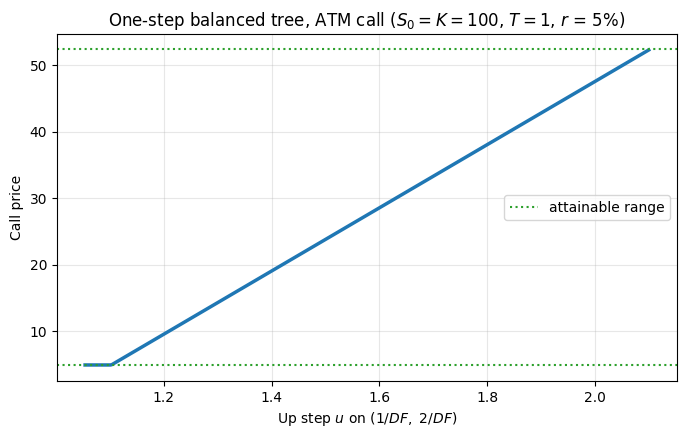

In [3]:
def step_discount_factor(rate: float, maturity: float, steps: int) -> float:
    return np.exp(-rate * maturity / steps)


def balanced_tree_call_price(spot_mult_up: float, spot: float, strike: float, maturity: float, rate: float,
                             steps: int) -> float:
    df = step_discount_factor(rate, maturity, steps)
    spot_mult_down = calcBalancedDownStep(spot_mult_up, df)
    if not 0 < spot_mult_down < 1 / df < spot_mult_up:
        raise ValueError(f'Invalid up step {spot_mult_up}: it must be in ({1 / df}, {2 / df}).')
    spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
    return create_discounted_price_tree(spot_tree, df, strike)[0][0]


def attainable_price_range(spot: float, strike: float, maturity: float, rate: float, steps: int) -> tuple[float, float]:
    df = step_discount_factor(rate, maturity, steps)
    return max(spot - strike * np.exp(-rate * maturity), 0.0), max(spot - strike * (df / 2)**steps, 0.0)


spot, rate, market_vol = 100.0, 0.05, 0.30
strike, maturity = 100.0, 1.0

df = step_discount_factor(rate, maturity, 1)
u_grid = np.linspace(1 / df, 2 / df, 400)[1:-1]
low, high = attainable_price_range(spot, strike, maturity, rate, 1)
plt.figure(figsize=(8, 4.5))
plt.plot(u_grid, [balanced_tree_call_price(u, spot, strike, maturity, rate, 1) for u in u_grid], linewidth=2.5)
plt.axhline(low, color='tab:green', linestyle=':', label='attainable range')
plt.axhline(high, color='tab:green', linestyle=':')
plt.title(f'One-step balanced tree, ATM call ($S_0 = K = {spot:g}$, $T = {maturity:g}$, $r$ = {rate:.0%})')
plt.xlabel('Up step $u$ on $(1/DF,\\ 2/DF)$')
plt.ylabel('Call price')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. The calibrator

$c(u) - c^*$ is continuous, monotone, negative at the lower end and positive at the upper end of the valid interval, so the root is bracketed.
A **bracketing root solver** (`scipy.optimize.brentq`) is therefore guaranteed to converge to the unique solution, to machine precision, in a few dozen tree evaluations.

The hint recommends `scipy.optimize.minimize` on the pricing error. I tried it, and it is not robust here: on the flat part the error is constant,
so a minimizer started there (or stepping there) stalls: in a first implementation with Nelder–Mead the pricing error got stuck at $2.8 \cdot 10^{-2}$
for the one-step call with $T = 0.25$, $K/S_0 = 0.7$ (its target is only $0.028$ above the lower limit).
Making it robust needs a bracketing step anyway, after which `brentq` alone is the simpler and exact choice.

In [4]:
def calibrate(target_price: float, spot: float, strike: float, maturity: float, rate: float, steps: int) -> float:
    """
    Up step of the Balanced Binomial Tree with the given number of steps that reproduces the target European call price.
    The one-step discount factor is exp(-rate * maturity / steps), i.e. the interest rate is flat.
    """
    low, high = attainable_price_range(spot, strike, maturity, rate, steps)
    if not low < target_price < high:
        raise ValueError(f'No balanced tree with {steps} step(s) reproduces the price {target_price:.6f}: '
                         f'it must be in ({low:.6f}, {high:.6f}).')
    df = step_discount_factor(rate, maturity, steps)
    eps = 1e-12
    return brentq(lambda u: balanced_tree_call_price(u, spot, strike, maturity, rate, steps) - target_price,
                  (1 + eps) / df, (2 - eps) / df, xtol=1e-14)

**Validation.** Round trip: price with a known up step, calibrate to that price, recover the up step. And a target outside the attainable range is rejected.

In [5]:
rows = []
for steps, true_u in [(1, 1.25), (3, 1.12), (10, 1.06), (50, 1.03)]:
    target = balanced_tree_call_price(true_u, spot, strike, maturity, rate, steps)
    u = calibrate(target, spot, strike, maturity, rate, steps)
    rows.append({'steps': steps, 'true u': true_u, 'calibrated u': u, '|u - true u|': abs(u - true_u)})
display(pd.DataFrame(rows).set_index('steps'))

try:
    calibrate(high + 1.0, spot, strike, maturity, rate, 1)
except ValueError as error:
    print('ValueError:', error)

,true u,calibrated u,|u - true u|
steps,,,
1,1.25,1.25,0.000000e+00
3,1.12,1.12,0.000000e+00
10,1.06,1.06,1.110223e-15
50,1.03,1.03,2.220446e-15


ValueError: No balanced tree with 1 step(s) reproduces the price 53.438529: it must be in (4.877058, 52.438529).


## 4. Same contract, different numbers of steps

ATM call, $K = 100$, $T = 1$, target = Black–Scholes price with $\sigma = 30\%$.

To compare trees with different $N$, write the calibrated steps as $u, d = (1 \pm x\sqrt{\Delta t})/DF$:
each step moves the discounted spot by $\pm x\sqrt{\Delta t}$ with probability $1/2$, so $x$ is the volatility of the tree (**tree volatility**), $x = (u \cdot DF - 1)/\sqrt{\Delta t}$.

In [6]:
def black_scholes_call(spot: float, strike: float, maturity: float, rate: float, vol: float) -> float:
    d1 = (np.log(spot / strike) + (rate + 0.5 * vol**2) * maturity) / (vol * np.sqrt(maturity))
    d2 = d1 - vol * np.sqrt(maturity)
    return spot * norm.cdf(d1) - strike * np.exp(-rate * maturity) * norm.cdf(d2)


def tree_vol(u: float, maturity: float, rate: float, steps: int) -> float:
    return (u * step_discount_factor(rate, maturity, steps) - 1) / np.sqrt(maturity / steps)


target = black_scholes_call(spot, strike, maturity, rate, market_vol)
print(f'Target price: {target:.6f}')

rows = []
for steps in [1, 2, 3, 4, 5, 10, 20, 50, 100, 200]:
    u = calibrate(target, spot, strike, maturity, rate, steps)
    df = step_discount_factor(rate, maturity, steps)
    rows.append({'steps': steps, 'DF per step': df, 'u': u, 'd': calcBalancedDownStep(u, df),
                 'tree vol x': tree_vol(u, maturity, rate, steps),
                 'repricing error': balanced_tree_call_price(u, spot, strike, maturity, rate, steps) - target})
demo1 = pd.DataFrame(rows).set_index('steps')
demo1

Target price: 14.231255


,DF per step,u,d,tree vol x,repricing error
steps,,,,,
1,0.951229,1.299218,0.803324,0.235855,1.421085e-14
2,0.975310,1.264293,0.786337,0.329621,-3.375078e-14
3,0.983471,1.178037,0.855576,0.274643,0.000000e+00
4,0.987578,1.172940,0.852217,0.316740,-1.421085e-14
5,0.990050,1.138481,0.881619,0.284323,3.552714e-15
10,0.995012,1.102251,0.907774,0.305962,0.000000e+00
20,0.997503,1.070324,0.934683,0.302545,9.947598e-14
50,0.999000,1.043574,0.958427,0.300741,1.634248e-13
100,0.999500,1.030539,0.970462,0.300235,4.032330e-13


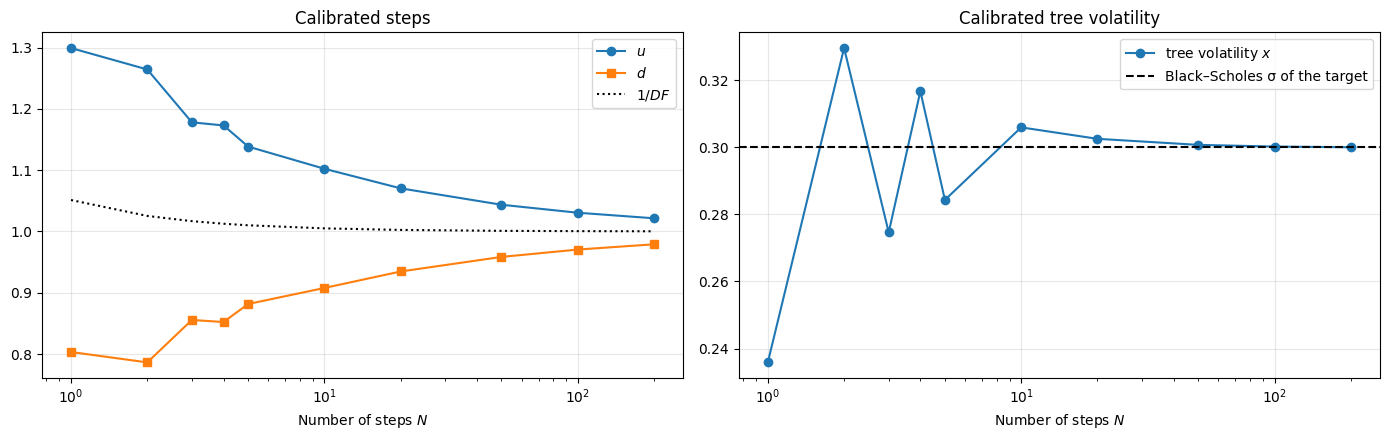

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(demo1.index, demo1['u'], 'o-', label='$u$')
axes[0].plot(demo1.index, demo1['d'], 's-', label='$d$')
axes[0].plot(demo1.index, 1 / demo1['DF per step'], 'k:', label='$1/DF$')
axes[0].set_title('Calibrated steps')
axes[1].plot(demo1.index, demo1['tree vol x'], 'o-', label='tree volatility $x$')
axes[1].axhline(market_vol, color='black', linestyle='--', label='Black–Scholes σ of the target')
axes[1].set_title('Calibrated tree volatility')
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('Number of steps $N$')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

Without scaling, i.e. using the 1-year discount factor $e^{-r}$ in every step, a 10-step tree discounts at $10r$ over the year.
Its lowest attainable price, $S_0 - K e^{-10r} = 39.35$, is then above the target $14.23$: no up step can reproduce the market price.

## 5. One-step tree, various contracts

Expiries $T \in \{0.25, 0.5, 1, 2, 5\}$, strikes $K/S_0 \in \{0.70, 0.75, \dots, 1.30\}$, targets = Black–Scholes with the same $\sigma = 30\%$.

In [8]:
expiries = [0.25, 0.5, 1.0, 2.0, 5.0]
strike_ratios = np.round(np.arange(0.7, 1.301, 0.05), 2)

rows = []
for T in expiries:
    for k in strike_ratios:
        target_k = black_scholes_call(spot, k * spot, T, rate, market_vol)
        u = calibrate(target_k, spot, k * spot, T, rate, steps=1)
        rows.append({'T': T, 'K/S0': k, 'u': u, 'tree vol x': tree_vol(u, T, rate, 1),
                     'repricing error': balanced_tree_call_price(u, spot, k * spot, T, rate, 1) - target_k})
demo2 = pd.DataFrame(rows)
print(f'max |repricing error| = {demo2["repricing error"].abs().max():.1e}')
demo2.pivot(index='K/S0', columns='T', values='u').round(4)

max |repricing error| = 1.8e-14


T,0.25,0.50,1.00,2.00,5.00
K/S0,,,,,
0.70,1.3257,1.3557,1.4232,1.5632,1.9905
0.75,1.2774,1.3121,1.3870,1.5349,1.9707
0.80,1.2319,1.2735,1.3564,1.5116,1.9546
0.85,1.1918,1.2415,1.3319,1.4932,1.9419
0.90,1.1604,1.2176,1.3141,1.4800,1.9325
0.95,1.1403,1.2028,1.3033,1.4718,1.9264
1.00,1.1333,1.1976,1.2992,1.4685,1.9234
1.05,1.1395,1.2017,1.3018,1.4698,1.9234
1.10,1.1576,1.2146,1.3107,1.4757,1.9262


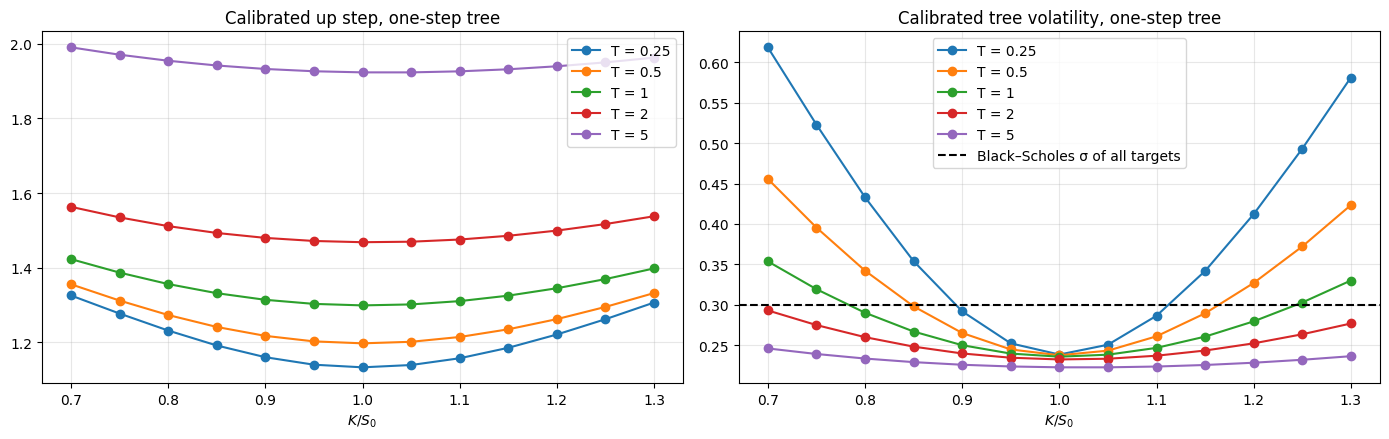

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for T in expiries:
    sub = demo2[demo2['T'] == T]
    axes[0].plot(sub['K/S0'], sub['u'], 'o-', label=f'T = {T:g}')
    axes[1].plot(sub['K/S0'], sub['tree vol x'], 'o-', label=f'T = {T:g}')
axes[0].set_title('Calibrated up step, one-step tree')
axes[1].axhline(market_vol, color='black', linestyle='--', label='Black–Scholes σ of all targets')
axes[1].set_title('Calibrated tree volatility, one-step tree')
for ax in axes:
    ax.set_xlabel('$K / S_0$')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## Results

* **More steps, same contract:** the repricing error is at machine precision for every $N$. $u$ and $d$ converge to $1/DF \to 1$,
  and the tree volatility converges to the volatility of the target (30.003% at $N = 200$), with the usual odd/even oscillation for small $N$:
  the balanced tree converges to Black–Scholes.
* **One step, various contracts:** every contract calibrates exactly, but to a different tree although all targets share one $\sigma$.
  With two outcomes and $S_0 d < K < S_0 u$, the price is linear in $x$: $c = \tfrac12\left(S_0(1 + x\sqrt{T}) - K e^{-rT}\right)$.
  At the money this gives $x \approx \sqrt{2/\pi}\,\sigma \approx 0.8\,\sigma$ (Black–Scholes ATM price $\approx 0.4\,S_0\sigma\sqrt{T}$); away from the money
  the Black–Scholes price comes from the tail of the lognormal distribution, which two points cannot represent, so $x$ rises: a smile.
  A one-step tree can match any single price, but not several strikes consistently.